# CNN으로 손글씨 숫자 분류하기 — MNIST (PyTorch)

**학습 목표**
1. MNIST 이미지와 정답(label)을 확인한다.
2. CNN에서 **합성곱 → 활성화(ReLU) → 풀링 → 완전연결층**이 하는 일을 설명한다.
3. CNN을 학습시키고 정확도와 예측 결과를 확인한다.
4. **특징맵(feature map)**을 직접 시각화한다.

> Colab 메뉴에서 **런타임 → 런타임 유형 변경 → T4 GPU**를 선택하면 더 빠릅니다. GPU가 없어도 CPU로 동작합니다.  
> 위에서 아래로 셀을 순서대로 실행하세요. (Shift + Enter)

## 1. 준비: 사용할 도구 불러오기
- `torch`: 딥러닝 계산
- `torchvision`: MNIST 데이터셋
- `matplotlib`: 이미지·그래프 표시

Colab에는 일반적으로 필요한 라이브러리가 설치되어 있어 별도의 설치 명령이 필요하지 않습니다.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# 결과를 최대한 비슷하게 재현하기 위한 설정
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# GPU가 있으면 GPU 사용, 없으면 CPU 사용
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("사용 장치:", device)
print("PyTorch 버전:", torch.__version__)

사용 장치: cpu
PyTorch 버전: 2.11.0+cpu


## 2. MNIST 데이터 불러오기
MNIST는 손글씨 숫자 **0~9**의 흑백 이미지 데이터입니다. 각 이미지는 **28×28 픽셀, 채널 1개**입니다.

수업 시간을 고려해 훈련 이미지 **12,000장만** 사용합니다(원본 훈련 60,000장). 테스트는 10,000장 전체를 사용합니다.

- `batch_size=128`: 이미지 128장을 한 번에 학습
- `shuffle=True`: 훈련 이미지 순서를 섞음

In [2]:
transform = transforms.ToTensor()  # 픽셀 0~255 → 0.0~1.0

train_full = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

USE_SMALL_DATASET = True   # False로 바꾸면 전체 60,000장 학습
TRAIN_SAMPLES = 12000
if USE_SMALL_DATASET:
    # 원본 데이터에서 무작위로 일부를 선택
    indices = torch.randperm(len(train_full))[:TRAIN_SAMPLES].tolist()
    train_dataset = Subset(train_full, indices)
else:
    train_dataset = train_full

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("훈련 이미지:", len(train_dataset), "장")
print("테스트 이미지:", len(test_dataset), "장")
image, label = train_dataset[0]
print("이미지 텐서 크기:", tuple(image.shape), "(채널, 높이, 너비)")
print("첫 이미지의 정답:", label)

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.09MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 160kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.51MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.54MB/s]


훈련 이미지: 12000 장
테스트 이미지: 10000 장
이미지 텐서 크기: (1, 28, 28) (채널, 높이, 너비)
첫 이미지의 정답: 6


## 3. 실제 데이터를 눈으로 확인하기
컴퓨터는 손글씨 이미지를 픽셀 숫자들의 배열로 처리합니다.

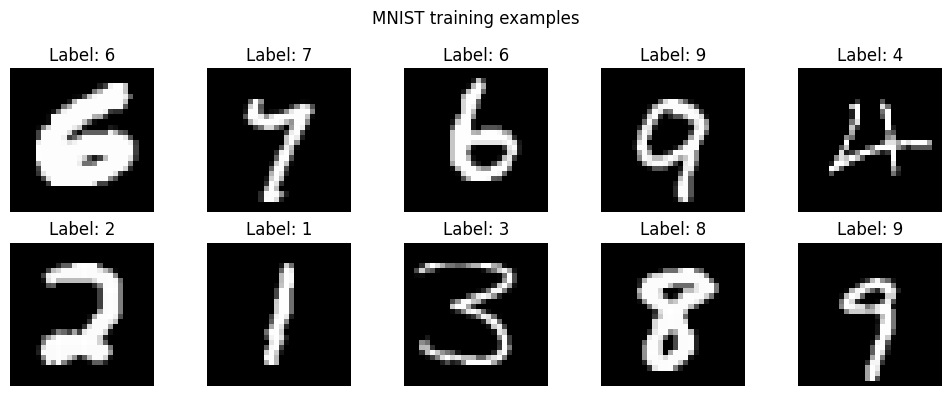

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.suptitle("MNIST training examples")
plt.tight_layout()
plt.show()

## 4. CNN 모델 만들기

**데이터가 이동하는 순서**

`입력(1×28×28) → 합성곱(16×28×28) → ReLU → 풀링(16×14×14) → 합성곱(32×14×14) → ReLU → 풀링(32×7×7) → 펼치기(1568) → 완전연결층(64) → 출력층(10)`

- **합성곱(Conv2d):** 필터를 이용해 선·모서리 등 특징을 찾음
- **ReLU:** 음수 출력을 0으로 바꾸는 비선형 활성화 함수
- **풀링(MaxPool2d):** 작은 영역의 최댓값을 남겨 특징맵 크기를 줄임
- **Flatten:** 3차원 특징맵을 1차원 벡터로 펼침
- **Linear:** 특징을 종합해 숫자 10개에 대한 점수 생성

> 마지막 10개의 값은 **확률이 아니라 점수(logits)**입니다. `CrossEntropyLoss`가 내부에서 필요한 계산을 하므로 학습 모델에 Softmax를 추가하지 않습니다.

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # 특징 추출: 합성곱 + 활성화 + 풀링
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        # 분류: 특징맵을 펼쳐 숫자 0~9의 점수 생성
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SimpleCNN().to(device)
print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)


### 모델 내부의 크기 직접 확인
- `32×7×7 = 1,568`: 마지막 풀링에서 만들어진 특징맵의 원소 수
- `10`: 숫자 0~9, 총 10개 클래스

In [5]:
sample_batch, _ = next(iter(train_loader))
x = sample_batch[:1].to(device)  # 이미지 1장, 크기 (1, 1, 28, 28)

with torch.no_grad():
    for layer in model.features:
        x = layer(x)
        print(f"{layer.__class__.__name__:12s} → {tuple(x.shape)}")
    scores = model.classifier(x)
    print(f"{'Classifier':12s} → {tuple(scores.shape)}")

Conv2d       → (1, 16, 28, 28)
ReLU         → (1, 16, 28, 28)
MaxPool2d    → (1, 16, 14, 14)
Conv2d       → (1, 32, 14, 14)
ReLU         → (1, 32, 14, 14)
MaxPool2d    → (1, 32, 7, 7)
Classifier   → (1, 10)


## 5. CNN 학습시키기

학습의 기본 순서: **예측(순전파) → 오차 계산(손실) → 기울기 계산(역전파) → 가중치 수정**

- 손실 함수: `CrossEntropyLoss()` (다중 클래스 분류)
- 최적화 알고리즘: `Adam`
- `epoch`: 전체 훈련 데이터를 한 번 학습하는 단위

In [6]:
LEARNING_RATE = 0.001
EPOCHS = 3  # 수업 시간에 맞춰 1~5 사이에서 변경 가능

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_losses = []
train_accuracies = []

for epoch in range(EPOCHS):
    model.train()  # 학습 모드
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # (1) 순전파: 예측 점수
        outputs = model(images)
        # (2) 손실 계산
        loss = loss_fn(outputs, labels)
        # (3) 이전 기울기 초기화 → 역전파
        optimizer.zero_grad()
        loss.backward()
        # (4) 가중치 수정
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_acc = 100 * correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)
    print(f"Epoch {epoch+1}/{EPOCHS} | 손실: {epoch_loss:.4f} | 훈련 정확도: {epoch_acc:.2f}%")

Epoch 1/3 | 손실: 0.9675 | 훈련 정확도: 71.16%
Epoch 2/3 | 손실: 0.2959 | 훈련 정확도: 90.88%
Epoch 3/3 | 손실: 0.2037 | 훈련 정확도: 93.98%


## 6. 학습 결과 그래프
손실이 감소하고 정확도가 증가하는지 확인합니다. 아래 그래프는 **훈련 데이터** 기준입니다.

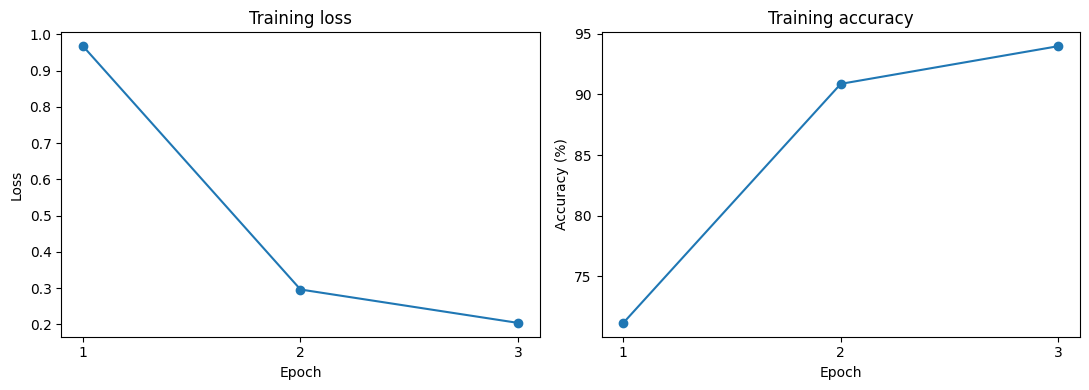

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
epochs = range(1, len(train_losses) + 1)
axes[0].plot(epochs, train_losses, marker="o")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[0].set_xticks(list(epochs))
axes[1].plot(epochs, train_accuracies, marker="o")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
axes[1].set_xticks(list(epochs))
plt.tight_layout()
plt.show()

## 7. 처음 보는 테스트 데이터로 평가하기
훈련에 사용하지 않은 테스트 이미지 **10,000장**에 대한 정확도를 계산합니다.

In [8]:
model.eval()  # 평가 모드
correct, total = 0, 0

with torch.no_grad():  # 평가에서는 역전파용 기울기 계산 불필요
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"테스트 정확도: {100 * correct / total:.2f}% ({correct}/{total})")

테스트 정확도: 94.96% (9496/10000)


## 8. CNN이 어떤 숫자를 예측하는지 확인하기
초록색 제목은 정답, 빨간색 제목은 오답을 뜻합니다.

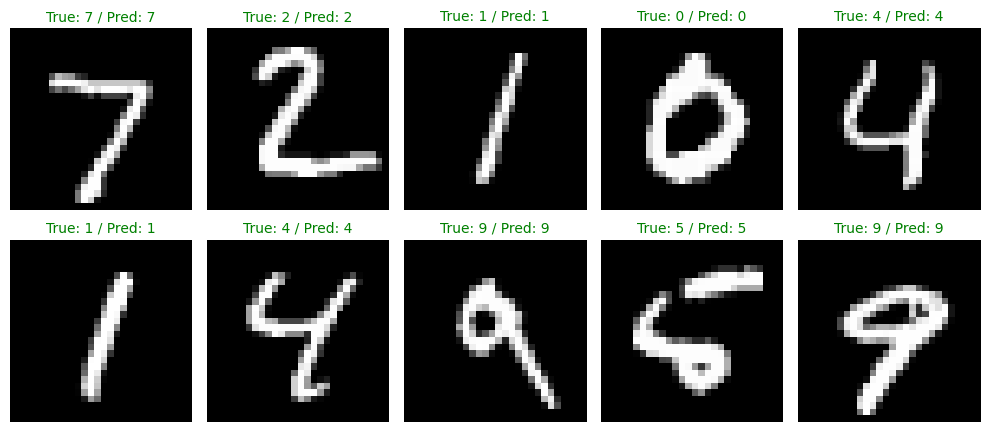

In [9]:
images, labels = next(iter(test_loader))
with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    is_correct = predictions[i].item() == labels[i].item()
    ax.set_title(f"True: {labels[i].item()} / Pred: {predictions[i].item()}",
                 color="green" if is_correct else "red", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. 핵심 시각화: 합성곱의 **특징맵(Feature Map)** 보기
한 장의 이미지가 **첫 번째 합성곱**을 통과하면 16개의 특징맵이 생깁니다. 각 필터가 다른 패턴에 반응하는 모습을 볼 수 있습니다.

> 특징맵은 단순히 이미지 크기를 뜻하는 용어가 아니라, 필터를 통과해 만들어진 **특징을 표현하는 값들의 배열**입니다. 여기서는 ReLU 적용 후의 결과를 보여 줍니다.

입력 크기: (1, 1, 28, 28)
첫 번째 특징맵 묶음 크기: (1, 16, 28, 28)


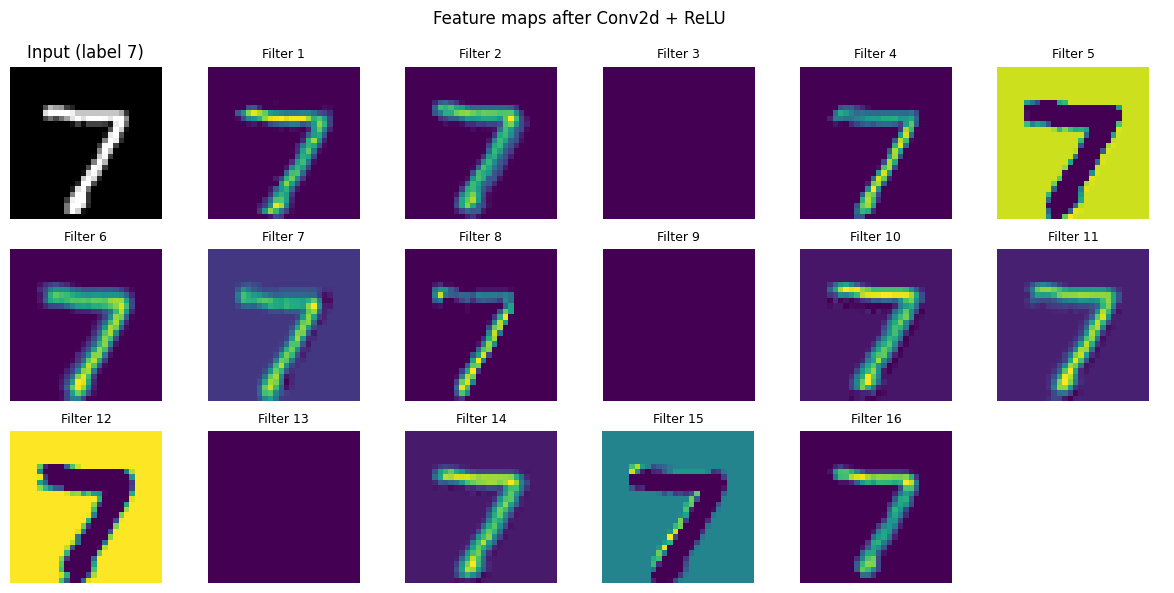

In [10]:
# 첫 번째 합성곱 + ReLU 결과 확인
image, label = test_dataset[0]
input_image = image.unsqueeze(0).to(device)  # (1, 1, 28, 28)

model.eval()
with torch.no_grad():
    conv_output = model.features[0](input_image)  # 첫 번째 합성곱
    feature_maps = model.features[1](conv_output)  # ReLU

print("입력 크기:", tuple(input_image.shape))
print("첫 번째 특징맵 묶음 크기:", tuple(feature_maps.shape))

fig, axes = plt.subplots(3, 6, figsize=(12, 6))
axes = axes.flat
axes[0].imshow(image.squeeze(), cmap="gray")
axes[0].set_title(f"Input (label {label})")
axes[0].axis("off")
for i in range(16):
    ax = axes[i + 1]
    ax.imshow(feature_maps[0, i].cpu(), cmap="viridis")
    ax.set_title(f"Filter {i+1}", fontsize=9)
    ax.axis("off")
axes[17].axis("off")
plt.suptitle("Feature maps after Conv2d + ReLU")
plt.tight_layout()
plt.show()

## 10. 학생 활동 (약 10~15분)

다음 항목을 **하나씩** 바꾸고 다시 학습해 결과를 비교해 보세요.

1. `EPOCHS = 3` → `1`, `5`: 학습 손실과 테스트 정확도는 어떻게 달라지나요?
2. `USE_SMALL_DATASET = True` → `False`: 학습 데이터가 많아지면 결과는 어떻게 달라지나요?
3. 첫 번째 `out_channels=16` → `8`: 특징맵 수가 어떻게 달라지나요? (**9번 셀의 시각화도 8개에 맞게 수정해야 함**)

**생각해 볼 질문**
- 합성곱 필터를 16개 쓰면 왜 특징맵도 16개 생길까요?
- 풀링으로 특징맵의 가로·세로가 줄어들면 어떤 장점이 있을까요?
- 훈련 정확도와 테스트 정확도가 서로 다를 수 있는 이유는 무엇일까요?

> **주의:** 모델 구조를 수정했다면 **4번 셀의 모델 생성부터 다시 실행**해야 합니다. 첫 번째 필터 개수만 바꿀 때는 다음 합성곱층의 `in_channels`도 같은 값으로 바꿔야 합니다.